# M2.1 — Understanding our EGFR/HER2 molecular dataset

**Exploratory data analysis (EDA) | AI in Cancer and Drug Development**

This notebook explores the **provisional M1.11 molecule-level labels** and **frozen M2.1 scaffold-disjoint split**. It reads local artifacts; it does **not** retrain models, alter labels, or rebuild the split.

**Scientific question:** Before comparing a Morgan-fingerprint Random Forest and a masked multi-task GNN, what data do we have, how are the EGFR/HER2 measurements distributed, and how does the scaffold split affect our evaluation?

> **Holdout rule.** We examine **test-set counts, label availability, and scaffold separation only**. All potency-distribution, activity-class, and descriptor analyses below use **training and validation** rows, and the paired potency scatter uses **training only**. Do not use the held-out test targets to choose features, thresholds, hyperparameters, or models. The final model comparison will evaluate the frozen test set once.

**Important biological caveat:** The M1.11 pIC50 labels come from curated reported IC50 measurements, but they remain *provisional*, not independently verified wild-type EGFR/HER2 biochemical ground truth. These plots do not demonstrate efficacy in cells, animals, or patients.

## Road map

1. Load and verify the frozen split outputs and SHA-256 hash.
2. Check dataset integrity, molecule identity, scaffold separation, and label masks.
3. Visualize partition sizes, missing target labels, and scaffold-group concentration.
4. Explore EGFR/HER2 pIC50 and dual-activity evidence **without opening test potency labels**.
5. Explore simple molecular properties and record interpretation notes for M2.2.

**Glossary:** A *molecule* is one distinct approved chemical identity (`m18c_structure_id`). A *scaffold* is a ring-and-linker framework shared by some molecules. An *observation* is one reported experimental measurement. A *provisional label* is one reconciled molecule–target pIC50 value, and a *mask* records whether that value is available (`1`) or withheld/missing (`0`). One molecule can carry labels for EGFR, HER2, or both.

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit import Chem, rdBase
from rdkit.Chem import Crippen, Descriptors, Lipinski, rdMolDescriptors

# VS Code/Jupyter can start in either the repository root or notebooks/.
start = Path.cwd().resolve()
repo_candidates = [start, *start.parents]
REPO = next(
    (p for p in repo_candidates if (p / "pyproject.toml").exists()),
    None,
)
if REPO is None:
    raise FileNotFoundError(
        "Open the notebook from the ai-dual-target-drug-discovery repository "
        "(or its notebooks/ folder), so pyproject.toml can be found."
    )

DATA = REPO / "data/interim/M2_1_scaffold_split_molecules.csv"
MANIFEST = REPO / "data/interim/M2_1_scaffold_split_manifest.csv"
SUMMARY = REPO / "reports/audits/M2_1_scaffold_split_summary.json"
EXPECTED_MANIFEST_SHA256 = "05968ca1ed2a16ca8165e8a28ececa0f361fc9e61a64ac2e69abb1e0e4b7423a"

for filename in [DATA, MANIFEST, SUMMARY]:
    if not filename.is_file():
        raise FileNotFoundError(
            f"Missing required M2.1 file: {filename}\n"
            "Run the M2.1 splitter first; never point this notebook at M1.11 instead."
        )

print("Repository:", REPO)
print("RDKit version:", rdBase.rdkitVersion)
print("Source CSV:", DATA.relative_to(REPO))

Repository: E:\rumman18GoogleDrive\JHU - Artificial Intelligence\EN7057148VL - AI in Cancer Detection and Drug Development\ai-dual-target-drug-discovery
RDKit version: 2026.09.1
Source CSV: data\interim\M2_1_scaffold_split_molecules.csv


## 1. Verify provenance before plotting

A **SHA-256 checksum** identifies the exact bytes of a file. We verify the saved split manifest against both your locally generated M2.1 summary and the checksum recorded at handoff. This guards against accidentally exploring a different split.

In [2]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

summary = json.loads(SUMMARY.read_text(encoding="utf-8"))
manifest_hash = sha256_file(MANIFEST)
data_hash = sha256_file(DATA)

assert manifest_hash == EXPECTED_MANIFEST_SHA256, (
    "Manifest hash differs from the frozen M2.1 handoff; investigate before continuing."
)
assert manifest_hash == summary["outputs"]["manifest_sha256"]
assert data_hash == summary["outputs"]["dataset_sha256"]
assert summary["random_seed"] == 714
assert summary["rdkit_version"] == rdBase.rdkitVersion

print("✓ Frozen manifest SHA-256:", manifest_hash)
print("✓ Dataset SHA-256:", data_hash)
print("✓ Seed:", summary["random_seed"])
print("✓ Split policy:", summary["policy"])
print("✓ Version and file-integrity checks passed")

✓ Frozen manifest SHA-256: 05968ca1ed2a16ca8165e8a28ececa0f361fc9e61a64ac2e69abb1e0e4b7423a
✓ Dataset SHA-256: 83a64d02e45ccd9a6310947efcd5cdef9bddc9603edcd55e1d207eb1cafc18b8
✓ Seed: 714
✓ Split policy: M2.1-rdkit-murcko-stereo-off-acyclic-identity-v1
✓ Version and file-integrity checks passed


## 2. Read the data and validate missing-label masks

A masked multi-task predictor produces an EGFR and HER2 estimate for the same chemical structure, but we can only use observed target labels for its loss. **An empty pIC50 cell is never an inactive measurement.**

In [3]:
df = pd.read_csv(DATA, keep_default_na=False, low_memory=False)
manifest = pd.read_csv(MANIFEST, keep_default_na=False, low_memory=False)

required = {
    "m18c_structure_id", "canonical_isomeric_smiles", "training_split",
    "scaffold_split", "scaffold_group_id", "scaffold_type", "murcko_scaffold_smiles",
    "egfr_mask", "her2_mask", "egfr_pic50", "her2_pic50",
    "paired_activity_class", "n_available_regression_tasks",
}
missing = required.difference(df.columns)
assert not missing, f"Missing expected columns: {sorted(missing)}"

for target in ("egfr", "her2"):
    mask_col, value_col = f"{target}_mask", f"{target}_pic50"
    df[mask_col] = pd.to_numeric(df[mask_col], errors="raise").astype(int)
    assert set(df[mask_col].unique()).issubset({0, 1})
    raw_values = df[value_col].astype(str).str.strip()
    assert raw_values[df[mask_col].eq(0)].eq("").all(), (
        f"Unexpected numerical label for masked {target.upper()} measurements"
    )
    df[value_col] = pd.to_numeric(raw_values.replace("", np.nan), errors="raise")
    assert df[value_col].notna().equals(df[mask_col].eq(1)), (
        f"The {target.upper()} label and availability mask disagree"
    )

df["n_available_regression_tasks"] = df["n_available_regression_tasks"].astype(int)
assert df["n_available_regression_tasks"].equals(df["egfr_mask"] + df["her2_mask"])
assert df["n_available_regression_tasks"].between(1, 2).all()
assert df["m18c_structure_id"].is_unique
assert df["canonical_isomeric_smiles"].is_unique
assert set(df["training_split"]) == {"train", "validation", "test"}
assert (df["training_split"] == df["scaffold_split"]).all()

# The manifest must be exactly the same molecule -> scaffold -> partition mapping.
check_cols = ["m18c_structure_id", "training_split", "scaffold_group_id", "scaffold_type",
              "murcko_scaffold_smiles", "egfr_mask", "her2_mask"]
check_manifest = manifest[check_cols].copy()
for target in ("egfr", "her2"):
    check_manifest[f"{target}_mask"] = check_manifest[f"{target}_mask"].astype(int)
merged = df[check_cols].merge(
    check_manifest, on="m18c_structure_id", how="outer", indicator=True,
    suffixes=("_dataset", "_manifest"), validate="one_to_one"
)
assert merged["_merge"].eq("both").all()
for col in check_cols[1:]:
    assert (merged[f"{col}_dataset"] == merged[f"{col}_manifest"]).all(), col

# The full-scaffold group is assigned to exactly one partition.
assert df.groupby("scaffold_group_id")["training_split"].nunique().max() == 1
assert len(df) == summary["audit"]["total_unique_molecules"] == 10866
assert df["scaffold_group_id"].nunique() == summary["audit"]["total_scaffold_groups"]
assert df["egfr_mask"].sum() == 9015
assert df["her2_mask"].sum() == 3206
assert int(((df["egfr_mask"] == 1) & (df["her2_mask"] == 1)).sum()) == 1355

print(f"✓ {len(df):,} unique molecules")
print(f"✓ {df['scaffold_group_id'].nunique():,} scaffold groups")
print("✓ Masks, manifest alignment, partition assignments, and scaffold separation passed")
# Show identifiers and availability only: NO test-set potency values.
safe_preview_cols = ["m18c_structure_id", "training_split", "scaffold_type", "egfr_mask", "her2_mask"]
display(df[safe_preview_cols].head(8))

✓ 10,866 unique molecules
✓ 3,895 scaffold groups
✓ Masks, manifest alignment, partition assignments, and scaffold separation passed


,m18c_structure_id,training_split,scaffold_type,egfr_mask,her2_mask
0,RDKISO1-0003991f2f4c0f08c43f6b0dff6c15234aa1dd...,train,ring_scaffold,1,0
1,RDKISO1-00057f173fe0dc0234da2a551c3e6673834f6c...,train,ring_scaffold,1,0
2,RDKISO1-0006a58a7564dd78397221f34700ab467fdd44...,validation,ring_scaffold,1,0
3,RDKISO1-001062c7183e90f5543bca156b58ac045bd497...,train,ring_scaffold,1,0
4,RDKISO1-00202c04cfb324ee4a31e834e589494fe60cf2...,validation,ring_scaffold,1,0
5,RDKISO1-002395b7374532881822e666129d618dd5a4ec...,train,ring_scaffold,1,1
6,RDKISO1-002594d62f60d587db880043323acd32361897...,train,ring_scaffold,1,0
7,RDKISO1-0026556dde65f47d17d651e220c2563bfaed16...,train,ring_scaffold,1,0


## 3. How many molecules and labels do we have?

We split **chemical identities**, not individual experimental rows. Because missing tasks are allowed, the number of EGFR labels, HER2 labels, and dual-labeled compounds differs in each partition.

In [4]:
order = ["train", "validation", "test"]
rows = []
for part in order:
    x = df.loc[df["training_split"].eq(part)]
    rows.append({
        "partition": part,
        "molecules": len(x),
        "EGFR labels": int(x["egfr_mask"].sum()),
        "HER2 labels": int(x["her2_mask"].sum()),
        "both labels": int((x["egfr_mask"] & x["her2_mask"]).sum()),
        "scaffold groups": x["scaffold_group_id"].nunique(),
    })
counts = pd.DataFrame(rows).set_index("partition")
for part in order:
    expected = summary["audit"]["by_partition"][part]
    for actual_col, expected_col in [
        ("molecules", "molecules"), ("EGFR labels", "EGFR_labels"),
        ("HER2 labels", "HER2_labels"), ("both labels", "dual_labeled"),
        ("scaffold groups", "scaffold_groups")
    ]:
        assert int(counts.loc[part, actual_col]) == expected[expected_col]
display(counts)

,molecules,EGFR labels,HER2 labels,both labels,scaffold groups
partition,,,,,
train,8692,7211,2565,1084,3115
validation,1087,902,320,135,389
test,1087,902,321,136,391


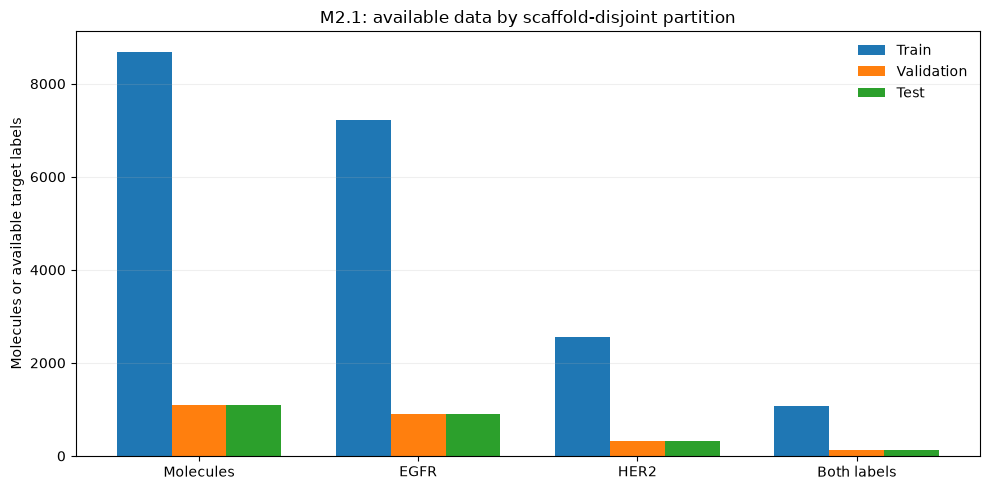

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
labels_to_plot = ["molecules", "EGFR labels", "HER2 labels", "both labels"]
x = np.arange(len(labels_to_plot))
width = 0.25
for idx, part in enumerate(order):
    ax.bar(x + (idx - 1) * width, counts.loc[part, labels_to_plot].to_numpy(),
           width=width, label=part.title())
ax.set_xticks(x, ["Molecules", "EGFR", "HER2", "Both labels"])
ax.set_ylabel("Molecules or available target labels")
ax.set_title("M2.1: available data by scaffold-disjoint partition")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

### Label coverage is not the same as dual inhibition

A molecule with *both* masks = 1 has been assigned provisional numerical values for both EGFR and HER2. It is **not automatically active on both proteins**. The four provisional activity categories are evaluated separately later, using only training/validation data.

,EGFR only,HER2 only,both targets
training_split,,,
train,6127,1481,1084
validation,767,185,135
test,766,185,136


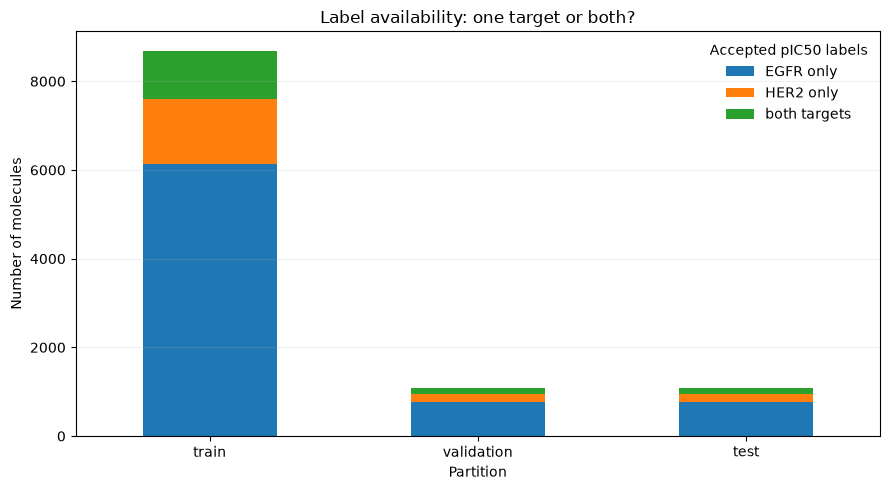

In [6]:
coverage = pd.DataFrame({
    "EGFR only": ((df.egfr_mask == 1) & (df.her2_mask == 0)).groupby(df.training_split).sum(),
    "HER2 only": ((df.egfr_mask == 0) & (df.her2_mask == 1)).groupby(df.training_split).sum(),
    "both targets": ((df.egfr_mask == 1) & (df.her2_mask == 1)).groupby(df.training_split).sum(),
}).reindex(order)
assert coverage.to_numpy().sum() == len(df)
display(coverage)
ax = coverage.plot.bar(stacked=True, figsize=(9, 5), rot=0)
ax.set_title("Label availability: one target or both?")
ax.set_xlabel("Partition")
ax.set_ylabel("Number of molecules")
ax.legend(frameon=False, title="Accepted pIC50 labels")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 4. How diverse are the molecular scaffolds?

**Bemis–Murcko scaffold:** the connected ring systems and linkers that form a molecule's central framework. Molecules can have different side groups but the same scaffold. All members of one scaffold group must be assigned together.

The split's **largest group contains 517 molecules**, so a whole-group split is intrinsically less flexible than row-wise random splitting. The six acyclic molecules are assigned an explicit **identity-based exception**: they are *not* scaffold-out-of-distribution examples under the usual meaning.

In [7]:
scaffold_table = (
    df.groupby("scaffold_group_id", as_index=False)
    .agg(molecules=("m18c_structure_id", "size"),
         partition=("training_split", "first"),
         scaffold_type=("scaffold_type", "first"),
         core_smiles=("murcko_scaffold_smiles", "first"))
    .sort_values(["molecules", "scaffold_group_id"], ascending=[False, True])
)
assert scaffold_table.molecules.max() == summary["audit"]["largest_group_size"]
print("Groups:", len(scaffold_table))
print("Singleton groups:", int(scaffold_table.molecules.eq(1).sum()))
print("Largest-group share:", f"{100 * scaffold_table.molecules.max() / len(df):.2f}%")
print("Top-10 group share:", f"{100 * scaffold_table.molecules.head(10).sum() / len(df):.2f}%")
print("Scaffold types (molecules):")
display(df.scaffold_type.value_counts().rename("molecules").to_frame())

visible = scaffold_table.head(12).copy()
visible["scaffold_group_id"] = visible["scaffold_group_id"].str.slice(0, 18) + "…"
visible["core_smiles"] = visible["core_smiles"].str.slice(0, 44)
display(visible)

Groups: 3895
Singleton groups: 2492
Largest-group share: 4.76%
Top-10 group share: 11.14%
Scaffold types (molecules):


,molecules
scaffold_type,
ring_scaffold,10860
acyclic_identity_group,6


,scaffold_group_id,molecules,partition,scaffold_type,core_smiles
957,BM-3e29b80f74c60c1…,517,train,ring_scaffold,c1ccc(Nc2ncnc3ccccc23)cc1
1218,BM-4f9efeb09982403…,113,validation,ring_scaffold,C1=C(C(Nc2ccc3ncccc3c2)c2cccnc2)NNN1C1CC1
312,BM-13cad05ca8f49c5…,102,test,ring_scaffold,c1ccccc1
1153,BM-4b4d2530bd5a63d…,91,train,ring_scaffold,c1ccc(Nc2ncnc3ccncc23)cc1
3487,BM-e22457441a5791f…,86,train,ring_scaffold,c1ccc(CNc2ncnc3[nH]c(-c4ccccc4)cc23)cc1
2434,BM-9f64913a9962f82…,84,train,ring_scaffold,c1ccc(Nc2ccnc3ccccc23)cc1
1306,BM-551752cfcf0833c…,66,train,ring_scaffold,c1nc(Nc2ccc(Oc3ccn4ncnc4c3)cc2)c2nc(N3CCNCC3
330,BM-14b934f6d79cd4c…,53,train,ring_scaffold,C1=Cc2n[nH]c3ccc(cc23)-c2cn[nH]c2OCCNCc2[nH]
2686,BM-af077a471c454e5…,50,train,ring_scaffold,O=C(Nc1ccccc1)c1nn(C2CCCNC2)c2ncncc12
1171,BM-4c8e4b345a309b3…,49,train,ring_scaffold,c1ccc(Nc2ncnc3cnccc23)cc1


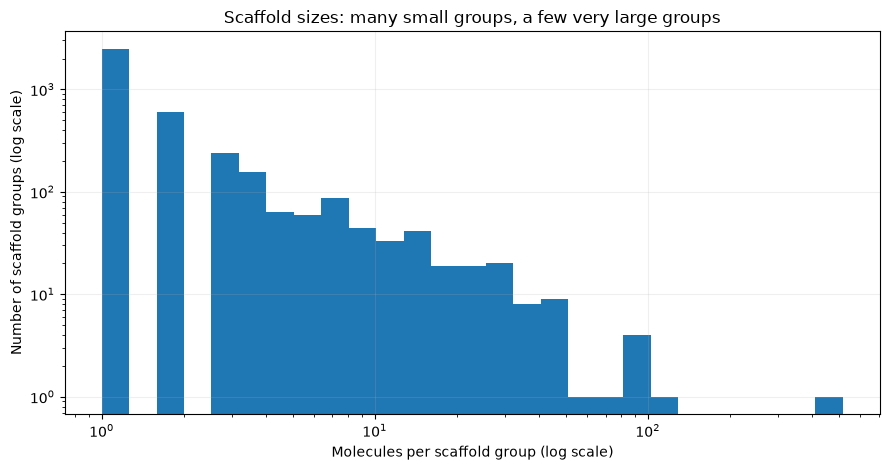

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
max_size = int(scaffold_table.molecules.max())
bins = np.geomspace(1, max_size + 1, 28)
ax.hist(scaffold_table.molecules, bins=bins)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Molecules per scaffold group (log scale)")
ax.set_ylabel("Number of scaffold groups (log scale)")
ax.set_title("Scaffold sizes: many small groups, a few very large groups")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 5. Potency distributions — training and validation only

**IC50** is the inhibitor concentration producing a 50% reduction in an assay response under specified conditions. Its log transform is

\[
\mathrm{pIC}_{50} = 9 - \log_{10}(\mathrm{IC}_{50}\;\text{in nM}).
\]

**Higher pIC50 means a lower reported IC50**. Under our *strictly below 1000 nM* activity convention, an exact measurement is active if **pIC50 > 6**. Exactly pIC50 = 6 is not active under this cutoff. Potency does not establish cellular or clinical efficacy.

We deliberately do **not** plot test-set pIC50 values here.

In [10]:
analysis_df = df.loc[df.training_split.isin(["train", "validation"])].copy()
print("Rows available to exploratory potency EDA:", len(analysis_df))

def summarise_potency(target: str) -> pd.DataFrame:
    name = f"{target}_pic50"
    rows = []
    for part in ["train", "validation"]:
        values = analysis_df.loc[analysis_df.training_split.eq(part), name].dropna()
        rows.append({
            "partition": part,
            "N": len(values),
            "median pIC50": values.median(),
            "10th percentile": values.quantile(0.10),
            "90th percentile": values.quantile(0.90),
            "active (>6), %": 100 * values.gt(6).mean(),
        })
    return pd.DataFrame(rows).set_index("partition")

print("EGFR")
display(summarise_potency("egfr").round(2))
print("HER2")
display(summarise_potency("her2").round(2))

Rows available to exploratory potency EDA: 9779
EGFR


,N,median pIC50,10th percentile,90th percentile,"active (>6), %"
partition,,,,,
train,7211,6.94,5.00,8.64,71.40
validation,902,7.06,5.15,8.63,74.72


HER2


,N,median pIC50,10th percentile,90th percentile,"active (>6), %"
partition,,,,,
train,2565,7.11,5.14,8.06,78.64
validation,320,7.07,4.82,8.09,75.62


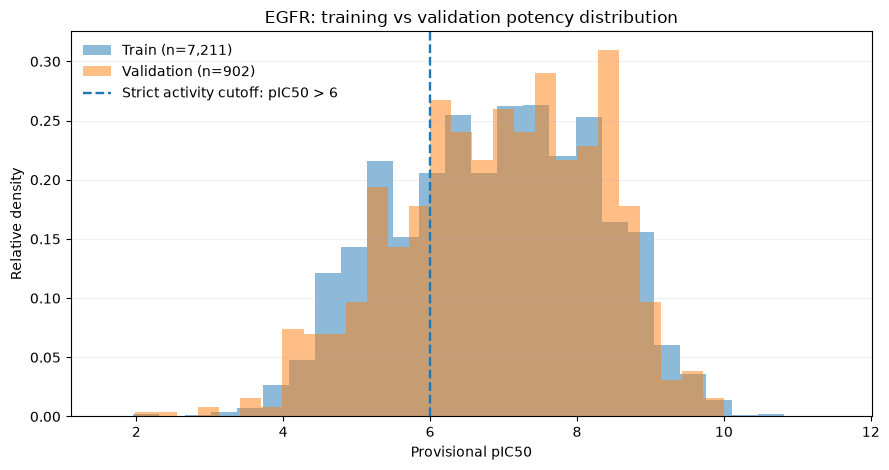

In [11]:
def plot_potency(target: str, title: str) -> None:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for part in ["train", "validation"]:
        v = analysis_df.loc[analysis_df.training_split.eq(part), f"{target}_pic50"].dropna()
        ax.hist(v, bins=28, density=True, alpha=0.5, label=f"{part.title()} (n={len(v):,})")
    ax.axvline(6, ls="--", lw=1.7, label="Strict activity cutoff: pIC50 > 6")
    ax.set_title(title)
    ax.set_xlabel("Provisional pIC50")
    ax.set_ylabel("Relative density")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()

plot_potency("egfr", "EGFR: training vs validation potency distribution")

In [ ]:
plot_potency("her2", "HER2: training vs validation potency distribution")

## 6. Paired activity: how many molecules have evidence for both targets?

For a molecule to count as **dual-active**, it must have accepted EGFR **and** HER2 labels with pIC50 **strictly above 6**. A molecule measured only against EGFR cannot be counted as HER2 inactive.

This is a *pre-model* look at available labels. It does not calculate predictive performance or PR-AUC. Test activity classes are intentionally excluded from this chart.

paired_activity_class,dual_active,dual_inactive,EGFR_only_active,HER2_only_active
training_split,,,,
train,685,233,109,57
validation,83,33,14,5


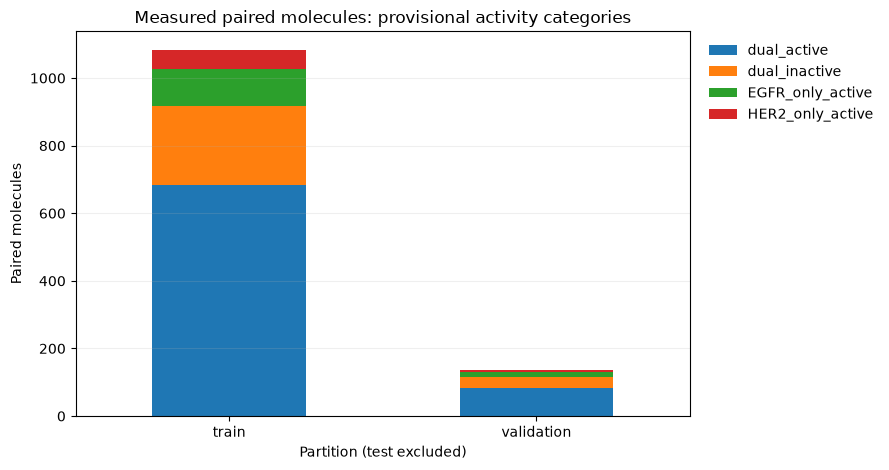

In [12]:
paired = analysis_df.loc[analysis_df.egfr_mask.eq(1) & analysis_df.her2_mask.eq(1)].copy()
classes = ["dual_active", "dual_inactive", "EGFR_only_active", "HER2_only_active"]
ct = pd.crosstab(paired.training_split, paired.paired_activity_class).reindex(
    index=["train", "validation"], columns=classes, fill_value=0
)
assert int(ct.to_numpy().sum()) == len(paired)
display(ct)
ax = ct.plot.bar(stacked=True, figsize=(9, 4.8), rot=0)
ax.set_title("Measured paired molecules: provisional activity categories")
ax.set_xlabel("Partition (test excluded)")
ax.set_ylabel("Paired molecules")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

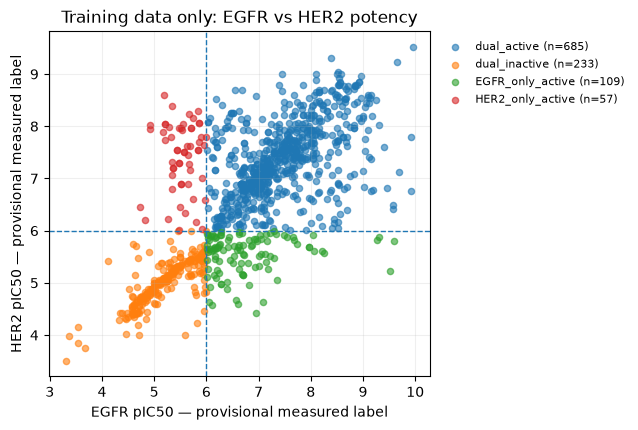

In [13]:
train_paired = paired.loc[paired.training_split.eq("train")]
fig, ax = plt.subplots(figsize=(6.5, 6))
for activity_class in classes:
    subset = train_paired.loc[train_paired.paired_activity_class.eq(activity_class)]
    if not subset.empty:
        ax.scatter(subset.egfr_pic50, subset.her2_pic50, s=20, alpha=0.6,
                   label=f"{activity_class} (n={len(subset):,})")
ax.axvline(6, ls="--", lw=1)
ax.axhline(6, ls="--", lw=1)
ax.set_xlabel("EGFR pIC50 — provisional measured label")
ax.set_ylabel("HER2 pIC50 — provisional measured label")
ax.set_title("Training data only: EGFR vs HER2 potency")
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(alpha=0.2)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

## 7. Where did the provisional labels come from?

M1.10 accepted a target label from either a single exact report or a tight set of repeated reports. **Repeated consensus is not automatically independent replication**, and the underlying protein construct/assay context was not fully sequence-verified. This is an important limitation of the target variable the models will learn.

Only **training + validation** statuses are summarized below.

In [14]:
for target in ["egfr", "her2"]:
    print(target.upper(), "support for accepted labels (train + validation only):")
    subset = analysis_df.loc[analysis_df[f"{target}_mask"].eq(1)]
    col = f"{target}_support"
    display(subset[col].value_counts(dropna=False).rename("molecule-target labels").to_frame())

EGFR support for accepted labels (train + validation only):


,molecule-target labels
egfr_support,
unreplicated_unverified,7192
repeated_unverified,921


HER2 support for accepted labels (train + validation only):


,molecule-target labels
her2_support,
unreplicated_unverified,2666
repeated_unverified,219


## 8. Basic molecular descriptors (no predictive modeling)

We calculate simple **structure-derived** properties from RDKit. These are descriptive chemistry summaries, not ADMET predictions or proof that a molecule is safe or synthesizable:

- **Molecular weight:** approximate molecular mass.
- **LogP:** calculated lipophilicity / preference for nonpolar vs aqueous environments.
- **TPSA:** topological polar surface area, associated with polarity.
- **Ring count:** number of rings in the molecular structure.

To keep exploratory inspection separate from the frozen test evaluation, this section processes **train and validation molecules only**.

In [15]:
records = []
for row in analysis_df[["m18c_structure_id", "canonical_isomeric_smiles", "training_split"]].itertuples(index=False):
    mol = Chem.MolFromSmiles(row.canonical_isomeric_smiles)
    if mol is None:
        raise ValueError(f"RDKit could not parse audited molecule {row.m18c_structure_id}")
    records.append({
        "structure_id": row.m18c_structure_id,
        "partition": row.training_split,
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "RingCount": Lipinski.RingCount(mol),
    })
props = pd.DataFrame(records)
display(props.groupby("partition")[["MolWt", "LogP", "TPSA", "RingCount"]].median().round(2))

,MolWt,LogP,TPSA,RingCount
partition,,,,
train,495.99,4.58,99.58,5.0
validation,509.97,4.73,100.93,5.0


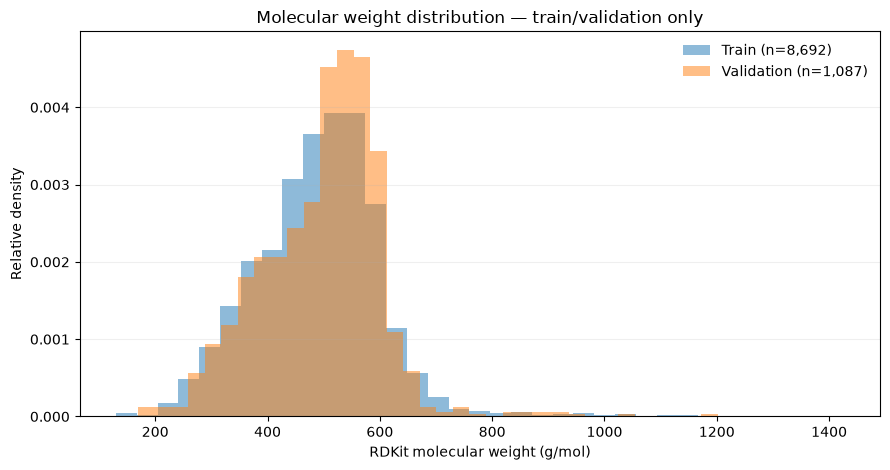

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for part in ["train", "validation"]:
    values = props.loc[props.partition.eq(part), "MolWt"]
    ax.hist(values, bins=35, density=True, alpha=0.5, label=f"{part.title()} (n={len(values):,})")
ax.set_xlabel("RDKit molecular weight (g/mol)")
ax.set_ylabel("Relative density")
ax.set_title("Molecular weight distribution — train/validation only")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 9. Interpretation and M2.2 readiness

Use the displayed *actual local results* to answer:

1. **Coverage:** Is HER2 label coverage substantially smaller than EGFR? Could this affect the reliability of per-target metrics?
2. **Scaffold sizes:** Does one large scaffold make some partitions more representative than others? Why do we group by scaffold instead of randomly splitting molecular rows?
3. **Assay evidence:** What fraction of the paired, training-only molecules are provisionally active against both targets? Does that guarantee similar prevalence in an independent study? (*No*.)
4. **Generalization:** Does having different Bemis–Murcko scaffolds guarantee fingerprint dissimilarity? (*No*; near-neighbor analogues can share strong similarity despite different core identifiers.*)
5. **Scientific validity:** What uncertainty remains after M1 curation? (Construct identity, assay heterogeneity, single-measurement support, duplicate source reporting.)

**What to preserve for M2.2:** the unchanged M2.1 split manifest/hash, training-only model fits, validation-only hyperparameter selection, identical test molecules for RF and GNN, target-specific masks, and clearly reported sample counts. Do **not** turn these EDA charts into model performance claims.

**Not done here:** model training, tuning, test-set potency exploration, de novo generation, docking, or experimental verification.